# 📦 Setup e importaciones

Importamos las librerías necesarias (`pandas`, `glob`, `os`) y clonamos el repositorio público de Jeff Sackmann desde GitHub, que contiene todos los datos históricos del circuito ATP en formato CSV.

In [ ]:
# =============================================================================
# ATP DATA LOADER
# Clona el repositorio de Jeff Sackmann y consolida los partidos ATP (1991-2024)
# =============================================================================

import pandas as pd
import glob
import os

# -----------------------------------------------------------------------------
# 1. CLONAR EL REPOSITORIO
# Usamos el comando de shell directamente desde Colab.
# Se clona en el directorio de trabajo actual (solo si no existe ya).
# -----------------------------------------------------------------------------
if not os.path.isdir('tennis_atp'):
    !git clone -q --depth 1 https://github.com/JeffSackmann/tennis_atp


fatal: destination path 'tennis_atp' already exists and is not an empty directory.


In [ ]:
# Evita que pandas trunce columnas al mostrar DataFrames en el notebook
pd.set_option('display.max_columns', None)

## 🔍 Localización y filtrado de archivos

Buscamos todos los CSV del repositorio que correspondan al ATP Tour principal entre 1991 y 2024. Se excluyen archivos de categorías menores o irrelevantes para el análisis: **futures**, **qualys**, **challengers** y **dobles**.

In [ ]:
# -----------------------------------------------------------------------------
# 2. LOCALIZAR LOS ARCHIVOS CSV DE PARTIDOS (1991-2024)
# glob nos da todos los archivos que coincidan con el patrón de nombre.
# Filtramos para quedarnos solo con los que contienen un año en el rango
# deseado y excluimos futures, qualy, challengers y dobles (circuitos
# menores o categorías distintas al ATP Tour principal).
# -----------------------------------------------------------------------------

# Palabras clave que identifican archivos que NO queremos cargar
EXCLUIR = ("futures", "qual", "chall", "doubles")

# Años de interés
ANIOS = set(str(y) for y in range(1991, 2025))

# Buscar todos los CSVs de partidos dentro del repositorio clonado
todos_los_csv = glob.glob("tennis_atp/atp_matches_*.csv")

# Filtrar: quedarse con los del rango de años y sin palabras excluidas
archivos = [
    f for f in todos_los_csv
    if not any(ex in os.path.basename(f) for ex in EXCLUIR)
    and any(anio in os.path.basename(f) for anio in ANIOS)
]

# Ordenar cronológicamente para mayor claridad
archivos.sort()
print(f"Archivos a cargar: {len(archivos)}")

Archivos a cargar: 34


## 🔗 Carga y concatenación de datos

Leemos cada CSV y los unimos en un único DataFrame. `low_memory=False` evita advertencias por columnas con tipos de datos mixtos, e `ignore_index=True` asegura un índice limpio y continuo en la tabla final.

In [ ]:
# -----------------------------------------------------------------------------
# 3. LEER Y CONCATENAR EN UN ÚNICO DATAFRAME
# Leemos cada CSV con low_memory=False para evitar advertencias de tipos
# mixtos y los juntamos en una sola tabla con pd.concat.
# ignore_index=True re-indexa las filas para que no haya duplicados
# en el índice.
# -----------------------------------------------------------------------------
df = pd.concat(
    [pd.read_csv(f, low_memory=False) for f in archivos],
    ignore_index=True
)

## 📊 Resumen del dataset

Imprimimos un diagnóstico rápido del DataFrame cargado: número de filas y columnas, rango de fechas cubierto y qué columnas contienen valores nulos. El DataFrame original no se modifica, la conversión de fechas es solo para el reporte.

In [ ]:
# -----------------------------------------------------------------------------
# 4. RESUMEN DEL DATAFRAME
# Imprimimos shape, rango de fechas y nulos por columna.
# tourney_date viene como entero (YYYYMMDD), lo convertimos solo para el
# reporte. No modificamos el DataFrame original (sin transformaciones).
# -----------------------------------------------------------------------------
print("========== RESUMEN ==========")

# Dimensiones
print(f"Shape: {df.shape[0]:,} filas x {df.shape[1]} columnas")

# Rango de fechas (conversión temporal solo para mostrar)
fechas = pd.to_datetime(df["tourney_date"], format="%Y%m%d", errors="coerce")
print(f"Rango de fechas:")
print(f"  Mínima : {fechas.min().date()}")
print(f"  Máxima : {fechas.max().date()}")

# Nulos por columna (solo las que tienen al menos uno)
nulos = df.isnull().sum()
nulos_con_datos = nulos[nulos > 0]
print(
    f"Columnas con valores nulos "
    f"({len(nulos_con_datos)} de {len(df.columns)}):"
)
print(nulos_con_datos.to_string())

print("==============================")

========== RESUMEN ==========
Shape: 108,375 filas x 49 columnas
Rango de fechas:
  Mínima : 1990-12-31
  Máxima : 2024-12-18
Columnas con valores nulos (33 de 49):
surface                  53
winner_seed           64441
winner_entry          95004
winner_ht              2248
winner_age                5
loser_seed            84167
loser_entry           86454
loser_hand                4
loser_ht               4490
loser_age                15
minutes               13274
w_ace                 10325
w_df                  10325
w_svpt                10325
w_1stIn               10325
w_1stWon              10325
w_2ndWon              10325
w_SvGms               10325
w_bpSaved             10325
w_bpFaced             10325
l_ace                 10325
l_df                  10325
l_svpt                10325
l_1stIn               10325
l_1stWon              10325
l_2ndWon              10325
l_SvGms               10325
l_bpSaved             10325
l_bpFaced             10325
winner_rank            

# 🧹 Preprocesamiento

Antes de explorar o modelar, necesitamos asegurarnos de que el dato crudo está en condiciones de ser analizado. En esta sección limpiamos y preparamos el DataFrame cargado anteriormente.

El preprocesamiento incluye:
- **Tipos de datos** — convertir columnas al tipo correcto (fechas, numéricos, categóricos)
- **Nulos** — decidir qué hacer con los valores faltantes en cada columna
- **Duplicados** — detectar y eliminar filas repetidas si las hay
- **Columnas irrelevantes** — descartar variables que no aporten información útil

El objetivo es obtener un DataFrame limpio, coherente y listo para el análisis, sin alterar la información original más de lo necesario.

## 🔎 Auditoría inicial

Antes de limpiar nada, inspeccionamos el estado real del DataFrame para tomar decisiones informadas. Revisamos cuatro aspectos clave:

- **Tipos de datos** — verificar que cada columna tiene el tipo correcto (fechas, numéricos, categóricos)
- **Nulos** — identificar qué columnas tienen valores faltantes y en qué proporción
- **Duplicados** — detectar si hay filas repetidas
- **Primeras filas** — un vistazo rápido a la estructura real del dato

In [ ]:
# =============================================================================
# AUDITORÍA INICIAL DEL DATAFRAME
# Antes de limpiar nada, inspeccionamos el estado real del dato crudo.
# Esto nos permite tomar decisiones informadas en cada paso del preprocesamiento.
# =============================================================================

print("=" * 60)
print("1. TIPOS DE DATOS")
print("=" * 60)
print(df.dtypes)

print("\n" + "=" * 60)
print("2. NULOS POR COLUMNA (solo las que tienen alguno)")
print("=" * 60)
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
auditoria_nulos = pd.DataFrame({
    "nulos": nulos,
    "% del total": nulos_pct
}).query("nulos > 0").sort_values("% del total", ascending=False)
print(auditoria_nulos.to_string())

print("\n" + "=" * 60)
print("3. DUPLICADOS")
print("=" * 60)
print(f"Filas duplicadas: {df.duplicated().sum()}")

print("\n" + "=" * 60)
print("4. PRIMERAS FILAS")
print("=" * 60)
print(df.head(3))

1. TIPOS DE DATOS
tourney_id                str
tourney_name              str
surface                   str
draw_size               int64
tourney_level             str
tourney_date            int64
match_num               int64
winner_id               int64
winner_seed           float64
winner_entry              str
winner_name               str
winner_hand               str
winner_ht             float64
winner_ioc                str
winner_age            float64
loser_id                int64
loser_seed            float64
loser_entry               str
loser_name                str
loser_hand                str
loser_ht              float64
loser_ioc                 str
loser_age             float64
score                     str
best_of                 int64
round                     str
minutes               float64
w_ace                 float64
w_df                  float64
w_svpt                float64
w_1stIn               float64
w_1stWon              float64
w_2ndWon              

In [ ]:
# =============================================================================
# CONVERSIÓN DE tourney_date A FECHA
# La columna tourney_date viene como entero en formato YYYYMMDD.
# La convertimos a datetime para poder operar con ella correctamente
# (filtros por fecha, cálculo de diferencias temporales, etc.)
# =============================================================================

df["tourney_date"] = pd.to_datetime(df["tourney_date"], format="%Y%m%d")

# Verificamos el cambio
print(f"Tipo de dato: {df['tourney_date'].dtype}")
print(
    f"Rango: {df['tourney_date'].min().date()} "
    f"-> {df['tourney_date'].max().date()}"
)
df["tourney_date"].head()

Tipo de dato: datetime64[us]
Rango: 1990-12-31 -> 2024-12-18


0   1990-12-31
1   1990-12-31
2   1990-12-31
3   1990-12-31
4   1990-12-31
Name: tourney_date, dtype: datetime64[us]

In [ ]:
# =============================================================================
# IMPUTACIÓN DE winner_seed / loser_seed Y winner_entry / loser_entry
# Los NaN en seed significan que el jugador no era cabeza de serie → 0
# Los NaN en entry significan que el jugador entró directamente al torneo → "Direct"
# No son datos faltantes reales, sino información implícita en el diseño del dato.
# =============================================================================

# Seed: 0 indica "no seeded"
df["winner_seed"] = df["winner_seed"].fillna(0)
df["loser_seed"]  = df["loser_seed"].fillna(0)

# Entry: "Direct" indica entrada directa al cuadro principal
df["winner_entry"] = df["winner_entry"].fillna("Direct")
df["loser_entry"]  = df["loser_entry"].fillna("Direct")

# Verificamos que no queden nulos en estas columnas
cols = ["winner_seed", "loser_seed", "winner_entry", "loser_entry"]
print(df[cols].isnull().sum())

winner_seed     0
loser_seed      0
winner_entry    0
loser_entry     0
dtype: int64


In [ ]:
# =============================================================================
# INSPECCIÓN DE FILAS SIN ESTADÍSTICAS DE PARTIDO
# Las columnas de estadísticas tienen exactamente los mismos nulos (10.325),
# lo que sugiere que son partidos completos sin datos registrados, no casos
# aislados. Antes de decidir qué hacer, inspeccionamos quiénes son.
# =============================================================================

# Usamos w_ace como columna representativa del bloque de estadísticas
sin_stats = df[df["w_ace"].isnull()]

print(f"Filas sin estadísticas: {len(sin_stats)}")
print(
    f"Rango de fechas: "
    f"{sin_stats['tourney_date'].min().date()} "
    f"-> {sin_stats['tourney_date'].max().date()}"
)
print(
    f"Distribución por superficie:"
    f"{sin_stats['surface'].value_counts()}"
)
print(f"Distribución por ronda: {sin_stats['round'].value_counts()}")

Filas sin estadísticas: 10325
Rango de fechas: 1990-12-31 -> 2024-11-04
Distribución por superficie:surface
Hard      4567
Clay      3921
Carpet    1352
Grass      432
Name: count, dtype: int64
Distribución por ronda: round
RR      8747
R32      394
R16      393
R64      281
QF       212
R128     152
SF        87
F         52
BR         7
Name: count, dtype: int64


In [ ]:
# =============================================================================
# ELIMINACIÓN DE COLUMNAS DE ESTADÍSTICAS IN-MATCH
# Para el modelo pre-partido solo usamos información disponible ANTES del partido.
# Las estadísticas de partido (aces, dobles faltas, puntos de saque, etc.)
# se generan durante el partido, por lo que no son válidas como features
# predictoras y las eliminamos para evitar data leakage.
# =============================================================================

cols_inmatch = [
    "minutes",
    "w_ace", "w_df", "w_svpt", "w_1stIn", "w_1stWon", "w_2ndWon",
    "w_SvGms", "w_bpSaved", "w_bpFaced",
    "l_ace", "l_df", "l_svpt", "l_1stIn", "l_1stWon", "l_2ndWon",
    "l_SvGms", "l_bpSaved", "l_bpFaced"
]

df = df.drop(columns=cols_inmatch)

# Verificamos que se han eliminado correctamente
print(f"Columnas restantes: {df.shape[1]}")
print(f"Nulos restantes:\n{df.isnull().sum()[df.isnull().sum() > 0]}")

Columnas restantes: 30
Nulos restantes:
surface                 53
winner_ht             2248
winner_age               5
loser_hand               4
loser_ht              4490
loser_age               15
winner_rank           1215
winner_rank_points    2203
loser_rank            2584
loser_rank_points     3567
dtype: int64


## 🩹 Imputación y limpieza de nulos restantes

Con las columnas de estadísticas in-match ya eliminadas, abordamos los nulos restantes caso por caso:

- **`surface`, `loser_hand`** — se imputan con la **moda** (valor más frecuente), al ser categóricas y tener muy pocos nulos
- **`winner_age`, `loser_age`, `winner_ht`, `loser_ht`** — se imputan con la **mediana**, resistente a outliers y representativa del circuito
- **`winner_rank`, `loser_rank`, `winner_rank_points`, `loser_rank_points`** — se **eliminan las filas** con nulos, ya que el ranking es la feature más importante del modelo y una imputación incorrecta aquí introduciría ruido significativo

In [ ]:
# =============================================================================
# IMPUTACIÓN Y LIMPIEZA DE NULOS RESTANTES
# Cada columna se trata según la naturaleza de sus nulos y su importancia
# para el modelo pre-partido.
# =============================================================================

# --- Categóricas: imputamos con la moda ---
df["surface"]    = df["surface"].fillna(df["surface"].mode()[0])
df["loser_hand"] = df["loser_hand"].fillna(df["loser_hand"].mode()[0])

# --- Numéricas continuas: imputamos con la mediana ---
for col in ["winner_age", "loser_age", "winner_ht", "loser_ht"]:
    df[col] = df[col].fillna(df[col].median())

# --- Ranking: eliminamos filas con nulos ---
# El ranking es la feature predictora más relevante;
# imputar valores falsos aquí dañaría la calidad del modelo.
cols_ranking = [
    "winner_rank", "loser_rank",
    "winner_rank_points", "loser_rank_points"
]
df = df.dropna(subset=cols_ranking)

# Verificamos que no queda ningún nulo
print(f"Shape final: {df.shape}")
print(f"Nulos restantes: {df.isnull().sum().sum()}")

Shape final: (104176, 30)
Nulos restantes: 0


## 📐 Outliers

Al inspeccionar las columnas numéricas clave encontramos valores claramente anómalos en las alturas:

**🔴 Errores evidentes**
- `winner_ht` — mínimo de **3cm**, imposible en cualquier contexto
- `loser_ht` — mínimo de **15cm**, también imposible

Estos valores son errores de registro y se eliminan filtrando fuera del rango válido **(165cm – 215cm)**.

**🟡 Valores límite pero válidos — se conservan**
- `winner_age` / `loser_age` — entre 15 y 44 años, posible en el circuito ATP histórico
- `winner_rank` / `loser_rank` — máximo ~2.100, plausible en wildcards sin ranking oficial
- `winner_rank_points` / `loser_rank_points` — máximo ~16.950, consistente con temporadas dominantes de Djokovic o Federer
- Alturas entre **165cm y 211cm** son perfectamente válidas en el circuito

**Criterio de eliminación:** se descartan las filas donde cualquiera de las alturas quede fuera del rango [165, 215]. Esto afecta únicamente a **13 filas (<0.01% del dataset)**, un volumen insignificante que no impacta en la calidad del dato.

In [ ]:
# =============================================================================
# INSPECCIÓN DE OUTLIERS EN COLUMNAS NUMÉRICAS CLAVE
# Antes de eliminar o corregir nada, revisamos la distribución de las columnas
# numéricas más sensibles para identificar valores anómalos o imposibles.
# =============================================================================

cols_revisar = [
    "winner_rank", "loser_rank",
    "winner_rank_points", "loser_rank_points",
    "winner_ht", "loser_ht",
    "winner_age", "loser_age"
]

print(df[cols_revisar].describe().round(2))

       winner_rank  loser_rank  winner_rank_points  loser_rank_points  \
count    104176.00   104176.00           104176.00          104176.00   
mean         73.72      115.89             1465.90             910.40   
std         113.48      171.86             1778.59            1018.25   
min           1.00        1.00                1.00               1.00   
25%          18.00       36.00              547.00             401.00   
50%          45.00       70.00              898.00             668.00   
75%          87.00      118.00             1635.00            1050.00   
max        2101.00     2159.00            16950.00           16950.00   

       winner_ht   loser_ht  winner_age  loser_age  
count  104176.00  104176.00   104176.00  104176.00  
mean      185.87     185.29       25.85      25.99  
std         6.76       6.65        3.81       3.90  
min         3.00      15.00       15.80      15.10  
25%       183.00     180.00       23.00      23.10  
50%       185.00     185

In [ ]:
# =============================================================================
# INSPECCIÓN DE FILAS CON ALTURAS ANÓMALAS
# Antes de eliminar nada, contamos cuántas filas quedarían afectadas
# por los umbrales definidos (165cm - 215cm).
# =============================================================================

mask_ht = (
    (df["winner_ht"] < 165) | (df["winner_ht"] > 215) |
    (df["loser_ht"]  < 165) | (df["loser_ht"]  > 215)
)

filas_afectadas = df[mask_ht]

pct = len(filas_afectadas) / len(df) * 100
print(
    f"Filas afectadas: {len(filas_afectadas)} "
    f"({pct:.2f}% del total)"
)
print(f"Valores concretos de altura anómala:")
print(
    filas_afectadas[
        ["winner_name", "winner_ht", "loser_name", "loser_ht"]
    ].to_string()
)

Filas afectadas: 13 (0.01% del total)
Valores concretos de altura anómala:
                       winner_name  winner_ht             loser_name  loser_ht
7954                  Jia Ping Xia      165.0   Ramayah Ramachandran     160.0
7955                 Jiu Hua Zhang      185.0   Ramayah Ramachandran     160.0
10775              Alex Antonitsch      188.0   Ramayah Ramachandran     160.0
11860               Chih Jung Chen      185.0   Ramayah Ramachandran     160.0
11862                  Yu Hui Lien      185.0   Ramayah Ramachandran     160.0
84337   Jorge Brian Panta Herreros        3.0          Martin Cuevas     191.0
89820   Jorge Brian Panta Herreros        3.0      Alejandro Mendoza     183.0
99386               Kasidit Samrej      191.0     Johannes Ingildsen      15.0
101817               Hiroki Moriya      168.0           Yuta Shimizu     163.0
102234            Marton Fucsovics      188.0  Viacheslav Bielinskyi      71.0
102251         Ramkumar Ramanathan      188.0     Johann

In [ ]:
# =============================================================================
# ELIMINACIÓN DE FILAS CON ALTURAS ANÓMALAS
# Solo 13 filas presentan alturas fuera del rango válido (165cm - 215cm),
# un volumen insignificante (<0.01% del total) que no afecta al dataset.
# Las eliminamos directamente.
# =============================================================================

df = df[~mask_ht].reset_index(drop=True)

# Verificamos el resultado
print(f"Shape tras eliminar outliers de altura: {df.shape}")

Shape tras eliminar outliers de altura: (104163, 30)


# ⚙️ Feature Engineering

Antes de construir nuevas variables, necesitamos resolver un problema estructural del dataset: **la asimetría**.

## El problema de la asimetría

El dataset original siempre coloca al ganador en las columnas `winner_*` y al perdedor en `loser_*`. Esto hace que el resultado ya esté codificado en la propia estructura del dato — un modelo entrenado así no aprendería patrones reales, sino simplemente que el jugador en `winner_*` siempre gana.

Ejemplo con un partido Nadal vs Federer:

| winner_name | winner_rank | loser_name | loser_rank |
|---|---|---|---|
| Nadal | 1 | Federer | 2 |

## La solución: simetrizar el dataset

Transformamos cada partido en **dos filas simétricas**, una por cada perspectiva, y añadimos una variable objetivo binaria `result` que indica si `player1` ganó (`1`) o perdió (`0`):

| player1_name | player1_rank | player2_name | player2_rank | result |
|---|---|---|---|---|
| Nadal | 1 | Federer | 2 | 1 |
| Federer | 2 | Nadal | 1 | 0 |

De esta forma el modelo aprende patrones reales — diferencia de ranking, superficie, edad, etc. — en lugar de aprender la posición en el DataFrame.

## Qué haremos en esta sección

1. **Winrate bayesiano** — calcular la tasa de victorias reciente de cada jugador en los últimos 30 partidos, usando Bayesian average para estabilizar estimaciones con poco historial
2. **Simetrizar** — reorganizar el dataset en formato neutro `player1` / `player2`
3. **Variables de diferencia** — crear features como `rank_diff`, `age_diff`, `ht_diff` y `winrate_diff` que capturen la distancia entre ambos jugadores
4. **Encoding** — convertir variables categóricas (`surface`, `round`, `hand`) a numéricas para que el modelo pueda procesarlas

## 📈 Winrate bayesiano

El ranking refleja la calidad histórica acumulada, pero no la forma reciente. Para capturarla
añadimos el **winrate bayesiano con ventana deslizante**: tasa de victorias de cada jugador
en sus últimos 30 partidos, calculada estrictamente antes del partido para evitar data leakage.

Un winrate simple `victorias / partidos` es inestable con pocos datos — un debutante con 1/1
tendría 100%. El **Bayesian average** corrige esto anclando la estimación hacia el 50% cuando
hay poco historial:

$$\text{winrate} = \frac{\text{victorias} + \text{prior}}{\text{partidos} + \text{prior} \times 2}$$

Con `prior = 5`, por debajo de ~10 partidos el winrate se aproxima a 0.5. A partir de ahí,
refleja el rendimiento real del jugador.

El resultado son dos columnas nuevas calculadas sobre `df` antes de simetrizar:
`winner_winrate` y `loser_winrate`.

In [ ]:
# =============================================================================
# WINRATE BAYESIANO CON VENTANA DESLIZANTE (30 partidos)
# Calculamos el winrate de cada jugador ANTES de cada partido para evitar
# data leakage. Usamos Bayesian average para estabilizar estimaciones con
# pocos partidos históricos.
#
# Fórmula: (victorias + prior) / (partidos + prior * 2)
# Valor por defecto si no hay historial previo: 0.5 (prior puro)
# =============================================================================

from tqdm.notebook import tqdm
tqdm.pandas()

# peso del prior: equivale a asumir 5 victorias y 5 derrotas previas
PRIOR = 5
VENTANA = 30  # número máximo de partidos anteriores a considerar


def calcular_winrate_bayesiano(series):
    """
    Calcula el winrate bayesiano con ventana deslizante para una serie
    de resultados binarios (1=victoria, 0=derrota) de un jugador.

    El cálculo es estrictamente retrospectivo: cada valor usa únicamente
    los VENTANA partidos anteriores, sin incluir el partido actual
    (shift(1)). Esto garantiza que no hay data leakage en el dataset
    de entrenamiento.

    Parameters
    ----------
    series : pd.Series
        Serie binaria de resultados ordenada cronológicamente
        (1=victoria, 0=derrota). Debe corresponder a un único jugador
        (usada dentro de groupby).

    Returns
    -------
    pd.Series
        Serie de floats en [0, 1] con el winrate bayesiano antes de
        cada partido. Devuelve 0.5 cuando no hay historial previo
        (prior puro).
    """
    victorias = (
        series.shift(1).rolling(VENTANA, min_periods=0).sum().fillna(0)
    )
    partidos = (
        series.shift(1).rolling(VENTANA, min_periods=0).count().fillna(0)
    )

    return (victorias + PRIOR) / (partidos + PRIOR * 2)


# --- Construir historial por jugador ---
print("[ 1 / 4 ] Construyendo historial por jugador...")

hist_winner = df[["tourney_date", "winner_id"]].copy()
hist_winner.columns = ["date", "player_id"]
hist_winner["win"] = 1

hist_loser = df[["tourney_date", "loser_id"]].copy()
hist_loser.columns = ["date", "player_id"]
hist_loser["win"] = 0

history = pd.concat([hist_winner, hist_loser], ignore_index=True)
history = history.sort_values(["player_id", "date"]).reset_index(drop=True)

n_jugadores = history["player_id"].nunique()
print(
    f"    Historial construido: {len(history):,} registros "
    f"({n_jugadores:,} jugadores únicos)"
)

# --- Aplicar la función por jugador ---
print("\n[ 2 / 4 ] Calculando winrate bayesiano por jugador...")

history["winrate"] = (
    history.groupby("player_id")["win"]
    .progress_transform(calcular_winrate_bayesiano)
)

print("    Winrate calculado correctamente.")

# --- Asignación vectorizada mediante merge ---
# drop_duplicates evita multiplicación de filas cuando un jugador
# tiene varios partidos el mismo día — conservamos el último registro
# del día, que corresponde al winrate más actualizado antes del partido.
print("\n[ 3 / 4 ] Asignando winrate al DataFrame original...")

winrate_df = history[["player_id", "date", "winrate"]].drop_duplicates(
    subset=["player_id", "date"], keep="last"
).copy()

# Merge para winner
df = df.merge(
    winrate_df.rename(columns={
        "player_id": "winner_id",
        "date"     : "tourney_date",
        "winrate"  : "winner_winrate"
    }),
    on=["winner_id", "tourney_date"],
    how="left"
)

# Merge para loser
df = df.merge(
    winrate_df.rename(columns={
        "player_id": "loser_id",
        "date"     : "tourney_date",
        "winrate"  : "loser_winrate"
    }),
    on=["loser_id", "tourney_date"],
    how="left"
)

# Jugadores sin historial previo -> 0.5 (prior puro)
df["winner_winrate"] = df["winner_winrate"].fillna(0.5)
df["loser_winrate"]  = df["loser_winrate"].fillna(0.5)

print("    Merge completado.")

# --- Verificación ---
print("\n[ 4 / 4 ] Verificación final:")
print(f"    Shape: {df.shape}  <- debe ser (104176, 32)")
print(df[["winner_winrate", "loser_winrate"]].describe().round(3))

[ 1 / 4 ] Construyendo historial por jugador...
    Historial construido: 208,326 registros (2,815 jugadores únicos)

[ 2 / 4 ] Calculando winrate bayesiano por jugador...


  0%|          | 0/2815 [00:00<?, ?it/s]

    Winrate calculado correctamente.

[ 3 / 4 ] Asignando winrate al DataFrame original...
    Merge completado.

[ 4 / 4 ] Verificación final:
    Shape: (104163, 32)  <- debe ser (104176, 32)
       winner_winrate  loser_winrate
count      104163.000     104163.000
mean            0.552          0.492
std             0.107          0.096
min             0.200          0.175
25%             0.475          0.425
50%             0.550          0.481
75%             0.625          0.550
max             0.875          0.875


## 🔄 Simetrización del dataset

Reorganizamos el dataset en formato neutro `player1` / `player2`. Cada partido original se convierte en **dos filas**:

- **Versión A** — el ganador ocupa `player1` → `result = 1`
- **Versión B** — el perdedor ocupa `player1` → `result = 0`

El resultado es un dataset con el **doble de filas** y un target perfectamente balanceado (50% victorias / 50% derrotas), donde el modelo no puede inferir el ganador por su posición en el DataFrame.

In [ ]:
# =============================================================================
# SIMETRIZACIÓN DEL DATASET
# Transformamos cada partido en dos filas simétricas para que el modelo
# no pueda inferir el resultado por la posición en el DataFrame.
# Cada partido se ve desde la perspectiva de ambos jugadores.
# =============================================================================

# --- Versión A: el ganador original es player1 → result = 1 ---
df_a = df.rename(columns={
    "winner_id"          : "player1_id",
    "winner_name"        : "player1_name",
    "winner_hand"        : "player1_hand",
    "winner_ht"          : "player1_ht",
    "winner_ioc"         : "player1_ioc",
    "winner_age"         : "player1_age",
    "winner_rank"        : "player1_rank",
    "winner_rank_points" : "player1_rank_points",
    "winner_seed"        : "player1_seed",
    "winner_entry"       : "player1_entry",
    "winner_winrate"     : "player1_winrate",
    "loser_id"           : "player2_id",
    "loser_name"         : "player2_name",
    "loser_hand"         : "player2_hand",
    "loser_ht"           : "player2_ht",
    "loser_ioc"          : "player2_ioc",
    "loser_age"          : "player2_age",
    "loser_rank"         : "player2_rank",
    "loser_rank_points"  : "player2_rank_points",
    "loser_seed"         : "player2_seed",
    "loser_entry"        : "player2_entry",
    "loser_winrate"      : "player2_winrate",
})
df_a["result"] = 1

# --- Versión B: el perdedor original es player1 → result = 0 ---
df_b = df.rename(columns={
    "loser_id"           : "player1_id",
    "loser_name"         : "player1_name",
    "loser_hand"         : "player1_hand",
    "loser_ht"           : "player1_ht",
    "loser_ioc"          : "player1_ioc",
    "loser_age"          : "player1_age",
    "loser_rank"         : "player1_rank",
    "loser_rank_points"  : "player1_rank_points",
    "loser_seed"         : "player1_seed",
    "loser_entry"        : "player1_entry",
    "loser_winrate"      : "player1_winrate",
    "winner_id"          : "player2_id",
    "winner_name"        : "player2_name",
    "winner_hand"        : "player2_hand",
    "winner_ht"          : "player2_ht",
    "winner_ioc"         : "player2_ioc",
    "winner_age"         : "player2_age",
    "winner_rank"        : "player2_rank",
    "winner_rank_points" : "player2_rank_points",
    "winner_seed"        : "player2_seed",
    "winner_entry"       : "player2_entry",
    "winner_winrate"     : "player2_winrate",
})
df_b["result"] = 0

# --- Concatenamos ambas versiones ---
df_sym = pd.concat([df_a, df_b], ignore_index=True).sort_values("tourney_date").reset_index(drop=True)

# Verificamos
print(f"Shape original:     {df.shape}")
print(f"Shape simetrizado:  {df_sym.shape}")
print(f"\nDistribución del target:\n{df_sym['result'].value_counts()}")

Shape original:     (104163, 32)
Shape simetrizado:  (208326, 33)

Distribución del target:
result
1    104163
0    104163
Name: count, dtype: int64


## ➕ Variables de diferencia

En lugar de pasar los valores absolutos de cada jugador por separado, creamos variables que capturan la **distancia relativa** entre ambos jugadores. El modelo no necesita saber que `player1` tiene ranking 10 — lo que realmente importa es que tiene **50 posiciones menos que `player2`**.

Todas las diferencias se calculan como `player1 - player2`:

| Variable | Interpretación |
|---|---|
| `rank_diff` | Negativo → player1 mejor rankeado |
| `rank_pts_diff` | Negativo → player1 con más puntos |
| `age_diff` | Negativo → player1 más joven |
| `ht_diff` | Negativo → player1 más bajo |
| `seed_diff` | Negativo → player1 mejor cabeza de serie |

La **simetría perfecta** de los resultados (media = 0, percentiles opuestos) confirma que la simetrización del paso anterior funcionó correctamente.

In [ ]:
# =============================================================================
# VARIABLES DE DIFERENCIA
# En lugar de pasar los valores absolutos de cada jugador por separado,
# creamos variables que capturen la distancia entre ambos jugadores.
# Esto es más informativo para el modelo: no importa tanto que player1
# tenga ranking 10, sino que tenga 50 posiciones menos que player2.
# Todas las diferencias se calculan como player1 - player2.
# Un valor negativo favorece a player1, positivo a player2 (ranking).
# =============================================================================

# Diferencia de ranking (negativo = player1 mejor rankeado)
df_sym["rank_diff"] = df_sym["player1_rank"] - df_sym["player2_rank"]

# Diferencia de puntos de ranking
df_sym["rank_pts_diff"] = (
    df_sym["player1_rank_points"] - df_sym["player2_rank_points"]
)

# Diferencia de edad
df_sym["age_diff"] = df_sym["player1_age"] - df_sym["player2_age"]

# Diferencia de altura
df_sym["ht_diff"] = df_sym["player1_ht"] - df_sym["player2_ht"]

# Diferencia de seed (0 = no seeded, diferencia de 0 es neutral)
df_sym["seed_diff"] = df_sym["player1_seed"] - df_sym["player2_seed"]

# Diferencia de winrate (negativo = player1 en mejor forma reciente)
df_sym["winrate_diff"] = (
    df_sym["player1_winrate"] - df_sym["player2_winrate"]
)

# Verificamos las nuevas columnas
print(df_sym[[
    "rank_diff", "rank_pts_diff", "age_diff",
    "ht_diff", "seed_diff", "winrate_diff"
]].describe().round(2))

       rank_diff  rank_pts_diff   age_diff    ht_diff  seed_diff  winrate_diff
count  208326.00      208326.00  208326.00  208326.00  208326.00     208326.00
mean        0.00           0.00       0.00       0.00       0.00          0.00
std       166.18        1876.84       5.19       9.19       7.33          0.14
min     -2125.00      -16641.00     -25.90     -41.00     -35.00         -0.60
25%       -44.00        -513.00      -3.40      -5.00      -1.00         -0.10
50%         0.00           0.00       0.00       0.00       0.00          0.00
75%        44.00         513.00       3.40       5.00       1.00          0.10
max      2125.00       16641.00      25.90      41.00      35.00          0.60


## 🗑️ Eliminación de rondas ER y BR

Las rondas **ER** y **Bronze Round (BR)** tienen una lógica distinta al resto del torneo — no son eliminación directa — y representan únicamente **84 filas (<0.04% del dataset)**. Un volumen tan pequeño aporta más ruido que información útil al modelo, por lo que se eliminan antes del encoding para mantener un orden de rondas limpio y coherente.

In [ ]:
# =============================================================================
# ELIMINACIÓN DE RONDAS ER Y BR
# Con solo 84 filas (<0.04% del dataset) y una lógica distinta al resto
# de rondas (no son eliminación directa), estas filas aportan más ruido
# que información útil al modelo. Las eliminamos antes del encoding.
# =============================================================================

df_sym = df_sym[~df_sym["round"].isin(["ER", "BR"])].reset_index(drop=True)

# Verificamos
print(f"Shape tras eliminar ER y BR: {df_sym.shape}")
print(f"\nRondas restantes:\n{df_sym['round'].value_counts()}")

Shape tras eliminar ER y BR: (208242, 39)

Rondas restantes:
round
R32     68440
R16     36456
R64     32506
R128    20904
QF      18324
RR      17478
SF       9364
F        4770
Name: count, dtype: int64


In [ ]:
# =============================================================================
# ENCODING DE VARIABLES CATEGÓRICAS
# Los modelos de ML no pueden trabajar con texto directamente.
# Convertimos las variables categóricas a numéricas usando dos estrategias:
# - Label Encoding para round: tiene un orden lógico progresivo (R128 -> F)
# - One-Hot Encoding para el resto: variables nominales sin orden implícito
# =============================================================================

# --- Label Encoding para round ---
# Las rondas siguen una progresión lógica de eliminación
round_order = {
    "R128": 1, "R64": 2, "R32": 3, "R16": 4,
    "QF": 5, "SF": 6, "F": 7
}
df_sym["round_encoded"] = df_sym["round"].map(round_order)

# --- One-Hot Encoding para el resto de categóricas ---
# No existe orden entre superficies, manos o tipos de entrada
cols_ohe = [
    "surface",
    "player1_hand", "player2_hand",
    "player1_entry", "player2_entry"
]
df_sym = pd.get_dummies(df_sym, columns=cols_ohe, drop_first=False)

# Verificamos
print(f"Shape tras encoding: {df_sym.shape}")
ohe_cols = [
    c for c in df_sym.columns
    if any(c.startswith(base) for base in
           ["surface", "player1_hand", "player2_hand",
            "player1_entry", "player2_entry"])
]
print(f"\nColumnas generadas por OHE:\n{ohe_cols}")

Shape tras encoding: (208242, 71)

Columnas generadas por OHE:
['surface_Carpet', 'surface_Clay', 'surface_Grass', 'surface_Hard', 'player1_hand_A', 'player1_hand_L', 'player1_hand_R', 'player1_hand_U', 'player2_hand_A', 'player2_hand_L', 'player2_hand_R', 'player2_hand_U', 'player1_entry_ALT', 'player1_entry_Alt', 'player1_entry_Direct', 'player1_entry_ITF', 'player1_entry_LL', 'player1_entry_PR', 'player1_entry_Q', 'player1_entry_S', 'player1_entry_SE', 'player1_entry_UP', 'player1_entry_W', 'player1_entry_WC', 'player2_entry_ALT', 'player2_entry_Alt', 'player2_entry_Direct', 'player2_entry_ITF', 'player2_entry_LL', 'player2_entry_PR', 'player2_entry_Q', 'player2_entry_S', 'player2_entry_SE', 'player2_entry_UP', 'player2_entry_W', 'player2_entry_WC']


In [ ]:
# =============================================================================
# INSPECCIÓN DE COLUMNAS ACTUALES
# Antes de seleccionar las features finales, revisamos todas las columnas
# disponibles para decidir cuáles conservar y cuáles descartar.
# =============================================================================

for i, col in enumerate(df_sym.columns):
    print(f"{i:3}  {col}")

  0  tourney_id
  1  tourney_name
  2  draw_size
  3  tourney_level
  4  tourney_date
  5  match_num
  6  player1_id
  7  player1_seed
  8  player1_name
  9  player1_ht
 10  player1_ioc
 11  player1_age
 12  player2_id
 13  player2_seed
 14  player2_name
 15  player2_ht
 16  player2_ioc
 17  player2_age
 18  score
 19  best_of
 20  round
 21  player1_rank
 22  player1_rank_points
 23  player2_rank
 24  player2_rank_points
 25  player1_winrate
 26  player2_winrate
 27  result
 28  rank_diff
 29  rank_pts_diff
 30  age_diff
 31  ht_diff
 32  seed_diff
 33  winrate_diff
 34  round_encoded
 35  surface_Carpet
 36  surface_Clay
 37  surface_Grass
 38  surface_Hard
 39  player1_hand_A
 40  player1_hand_L
 41  player1_hand_R
 42  player1_hand_U
 43  player2_hand_A
 44  player2_hand_L
 45  player2_hand_R
 46  player2_hand_U
 47  player1_entry_ALT
 48  player1_entry_Alt
 49  player1_entry_Direct
 50  player1_entry_ITF
 51  player1_entry_LL
 52  player1_entry_PR
 53  player1_entry_Q
 54  player1

## 🎯 Selección de features finales

Eliminamos las columnas que no aportan valor predictivo al modelo:

- **Identificadores y texto** — `tourney_id`, `tourney_name`, `match_num`, `player1_id`, `player2_id`, `player1_name`, `player2_name`, `player1_ioc`, `player2_ioc` no son features generalizables
- **`score`** — es el resultado del partido, incluirla sería data leakage
- **`round`** — ya está codificada en `round_encoded`
- **Manos anómalas** — `player1_hand_A`, `player1_hand_U`, `player2_hand_A`, `player2_hand_U` representan apenas 89 casos (<0.05%)
- **Entries minoritarias** — categorías con muy pocos casos que aportan más ruido que información

Conservamos `tourney_level`, `draw_size` y `best_of` por su relevancia contextual (nivel del torneo, tamaño del cuadro y formato de partido).

In [ ]:
# =============================================================================
# SELECCIÓN DE FEATURES FINALES
# Eliminamos columnas que no aportan valor predictivo:
# identificadores, texto, data leakage, categorías anómalas y minoritarias.
# =============================================================================

cols_eliminar = [
    # Identificadores y texto
    "tourney_id", "tourney_name", "match_num",
    "player1_id", "player2_id",
    "player1_name", "player2_name",
    "player1_ioc", "player2_ioc",
    # Data leakage
    "score",
    # Round ya codificada
    "round",
    # Valores absolutos de winrate — ya capturados en winrate_diff
    "player1_winrate", "player2_winrate",
    # Manos anómalas
    "player1_hand_A", "player1_hand_U",
    "player2_hand_A", "player2_hand_U",
    # Entries minoritarias
    "player1_entry_ALT", "player1_entry_Alt", "player1_entry_ITF",
    "player1_entry_SE", "player1_entry_UP", "player1_entry_W",
    "player2_entry_ALT", "player2_entry_Alt", "player2_entry_ITF",
    "player2_entry_SE", "player2_entry_UP", "player2_entry_W",
]

df_sym = df_sym.drop(columns=cols_eliminar)

# Verificamos
print(f"Shape final: {df_sym.shape}")
print(f"\nColumnas finales:")
for i, col in enumerate(df_sym.columns):
    print(f"{i:3}  {col}")

Shape final: (208242, 42)

Columnas finales:
  0  draw_size
  1  tourney_level
  2  tourney_date
  3  player1_seed
  4  player1_ht
  5  player1_age
  6  player2_seed
  7  player2_ht
  8  player2_age
  9  best_of
 10  player1_rank
 11  player1_rank_points
 12  player2_rank
 13  player2_rank_points
 14  result
 15  rank_diff
 16  rank_pts_diff
 17  age_diff
 18  ht_diff
 19  seed_diff
 20  winrate_diff
 21  round_encoded
 22  surface_Carpet
 23  surface_Clay
 24  surface_Grass
 25  surface_Hard
 26  player1_hand_L
 27  player1_hand_R
 28  player2_hand_L
 29  player2_hand_R
 30  player1_entry_Direct
 31  player1_entry_LL
 32  player1_entry_PR
 33  player1_entry_Q
 34  player1_entry_S
 35  player1_entry_WC
 36  player2_entry_Direct
 37  player2_entry_LL
 38  player2_entry_PR
 39  player2_entry_Q
 40  player2_entry_S
 41  player2_entry_WC


In [ ]:
# =============================================================================
# INSPECCIÓN DE tourney_level
# Revisamos los valores únicos y su frecuencia antes de codificarla.
# =============================================================================

print(df_sym["tourney_level"].value_counts())

tourney_level
A    120798
M     37384
G     34092
D     14708
F      1140
O       120
Name: count, dtype: int64


In [ ]:
# =============================================================================
# ENCODING DE tourney_level
# La variable tiene un orden lógico de prestigio, por lo que usamos
# Label Encoding en lugar de OHE para capturar la jerarquía del torneo.
# A=1 → D=2 → O=3 → F=4 → M=5 → G=6
# =============================================================================

tourney_level_order = {
    "A": 1,  # ATP 250/500
    "D": 2,  # Davis Cup
    "O": 3,  # Olympics
    "F": 4,  # ATP Finals
    "M": 5,  # Masters 1000
    "G": 6   # Grand Slam
}

df_sym["tourney_level"] = df_sym["tourney_level"].map(tourney_level_order)

# Verificamos
print(df_sym["tourney_level"].value_counts().sort_index())
print(f"\nNulos tras encoding: {df_sym['tourney_level'].isnull().sum()}")

tourney_level
1    120798
2     14708
3       120
4      1140
5     37384
6     34092
Name: count, dtype: int64

Nulos tras encoding: 0


## 📅 Tratamiento de tourney_date

La fecha del torneo no es usable directamente como feature, pero contiene información temporal valiosa. Seguimos dos pasos:

- **Extraemos el año** como variable numérica — captura la evolución del juego a lo largo del tiempo (1991-2024)
- **Conservamos `tourney_date` aparte** — la necesitaremos para hacer el split temporal train/test correctamente, evitando que el modelo entrene con datos del futuro

In [ ]:
# =============================================================================
# TRATAMIENTO DE tourney_date
# La fecha no es usable directamente como feature numérica.
# Extraemos el año para capturar tendencias temporales y guardamos
# la fecha completa aparte para usarla en el split temporal train/test.
# =============================================================================

# Guardamos tourney_date aparte para el split temporal
tourney_dates = df_sym["tourney_date"].copy()

# Extraemos el año como variable numérica
df_sym["year"] = df_sym["tourney_date"].dt.year

# Eliminamos tourney_date del dataset de features
df_sym = df_sym.drop(columns=["tourney_date"])

# Verificamos
print(f"Shape: {df_sym.shape}")
print(f"\nDistribución por año (primeros y últimos):")
print(df_sym["year"].value_counts().sort_index().iloc[[0,1,2,-3,-2,-1]])

Shape: (208242, 42)

Distribución por año (primeros y últimos):
year
1991    6760
1992    6714
1993    6990
2022    5780
2023    5878
2024    6056
Name: count, dtype: int64


## ⚖️ Escalado de features

Escalamos las variables numéricas continuas para que todos los modelos trabajen en igualdad de condiciones. Aunque Random Forest y XGBoost no lo necesitan, la regresión logística sí es sensible a las diferencias de escala entre features.

Usamos **StandardScaler** (media=0, desviación estándar=1), que es el método más habitual para modelos de clasificación. Las columnas binarias resultado del OHE no se escalan, ya que ya están en el rango [0, 1].

In [ ]:
# =============================================================================
# IMPUTACIÓN Y ESCALADO DE FEATURES NUMÉRICAS
# Aplicamos StandardScaler solo a las columnas numéricas continuas.
# Las columnas binarias (OHE) no se escalan al ya estar en rango [0,1].
# Antes de escalar imputamos NaN: mediana para numéricas (rankings sin dato),
# 0 para binarias (ausencia de categoría en OHE).
# =============================================================================

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Columnas binarias que NO escalamos
cols_binarias = [
    c for c in df_sym.columns
    if df_sym[c].nunique() == 2 and c != "result"
]

# Columnas numéricas continuas que SÍ escalamos (excluimos el target)
cols_escalar = [c for c in df_sym.columns
                if c not in cols_binarias
                and c != "result"]

# Imputamos NaN: mediana para numéricas, 0 para binarias OHE
imputer = SimpleImputer(strategy="median")
df_sym[cols_escalar] = imputer.fit_transform(df_sym[cols_escalar])
df_sym[cols_binarias] = df_sym[cols_binarias].fillna(0)

# Ajustamos y transformamos
scaler = StandardScaler()
df_sym[cols_escalar] = scaler.fit_transform(df_sym[cols_escalar])

# Verificamos
print(f"Columnas escaladas ({len(cols_escalar)}): {cols_escalar}")
print(f"Estadísticas tras escalado:")
print(df_sym[cols_escalar].describe().round(2))

Columnas escaladas (20): ['draw_size', 'tourney_level', 'player1_seed', 'player1_ht', 'player1_age', 'player2_seed', 'player2_ht', 'player2_age', 'player1_rank', 'player1_rank_points', 'player2_rank', 'player2_rank_points', 'rank_diff', 'rank_pts_diff', 'age_diff', 'ht_diff', 'seed_diff', 'winrate_diff', 'round_encoded', 'year']
Estadísticas tras escalado:
       draw_size  tourney_level  player1_seed  player1_ht  player1_age  \
count  208242.00      208242.00     208242.00   208242.00    208242.00   
mean        0.00           0.00         -0.00        0.00        -0.00   
std         1.00           1.00          1.00        1.00         1.00   
min        -1.37          -0.77         -0.47       -3.09        -2.81   
25%        -0.60          -0.77         -0.47       -0.84        -0.73   
50%        -0.60          -0.77         -0.47       -0.09        -0.06   
75%         0.23           1.13          0.11        0.66         0.64   
max         1.88           1.60          6.40    

# 🤖 Entrenamiento y comparación de modelos

Con el dataset preparado — simetrizado, con features de diferencia, winrate bayesiano,
encoding y escalado — entramos en la fase de modelado.

Entrenamos y comparamos tres modelos de complejidad creciente, siguiendo la estrategia
recomendada por CRISP-DM: empezar simple y añadir complejidad solo si está justificada
por los resultados.

| Modelo | Rol |
|---|---|
| Logistic Regression | Baseline — simple e interpretable |
| Random Forest | Modelo intermedio — robusto y estable |
| XGBoost | Modelo final — estado del arte en datos tabulares |

Los tres se evalúan con las mismas métricas (AUC-ROC, F1, Accuracy) y el mismo
split temporal, lo que garantiza una comparación justa.

## 🌲 Random Forest con Grid Search

Entrenamos el primer modelo del proyecto — Random Forest — usando **Grid Search** para
encontrar la combinación óptima de hiperparámetros en lugar de usar valores por defecto.

### Split temporal

El dataset se divide por fecha, no de forma aleatoria. Todo lo anterior a 2021 es train;
desde 2021 en adelante es test. Esto simula un escenario real: el modelo aprende con
partidos del pasado y se evalúa con partidos que no ha visto, respetando el orden cronológico.

### Grid Search con StratifiedKFold

Grid Search prueba sistemáticamente todas las combinaciones posibles de hiperparámetros
y selecciona la que maximiza el AUC-ROC en validación cruzada. Los parámetros explorados son:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `n_estimators` | 100, 200 | Número de árboles del bosque |
| `max_depth` | 10, 20, None | Profundidad máxima de cada árbol |
| `min_samples_split` | 2, 10 | Mínimo de muestras para dividir un nodo |
| `min_samples_leaf` | 1, 4 | Mínimo de muestras en cada hoja |
| `max_features` | sqrt, log2 | Features consideradas en cada split |

Se evalúan **48 combinaciones × 5 folds = 240 fits** en total. Se usa `StratifiedKFold`
con `shuffle=False` para preservar el orden temporal dentro de la validación cruzada.

### Evaluación y feature importance

Una vez identificados los mejores hiperparámetros, el modelo se re-entrena sobre todo
el conjunto de train y se evalúa sobre test. Se reportan accuracy, AUC-ROC, classification
report, matriz de confusión y un ranking de las 15 features más importantes — lo que
permite interpretar qué variables tienen más peso en las predicciones del modelo.

Train: 185,122 filas (50.0% victorias)
Test : 23,120 filas (50.0% victorias)

Total combinaciones: 48 x 5 folds = 240 fits


Grid Search:   0%|          | 0/240 [00:00<?, ?fit/s]


Mejores hiperparámetros:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 200}
Mejor AUC-ROC en CV: 0.7690

RESULTADOS — RANDOM FOREST (Grid Search)
Accuracy : 0.6909
AUC-ROC  : 0.7607

Classification report:
              precision    recall  f1-score   support

           0       0.69      0.69      0.69     11560
           1       0.69      0.69      0.69     11560

    accuracy                           0.69     23120
   macro avg       0.69      0.69      0.69     23120
weighted avg       0.69      0.69      0.69     23120



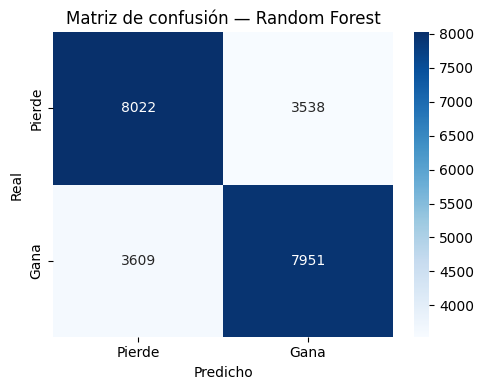

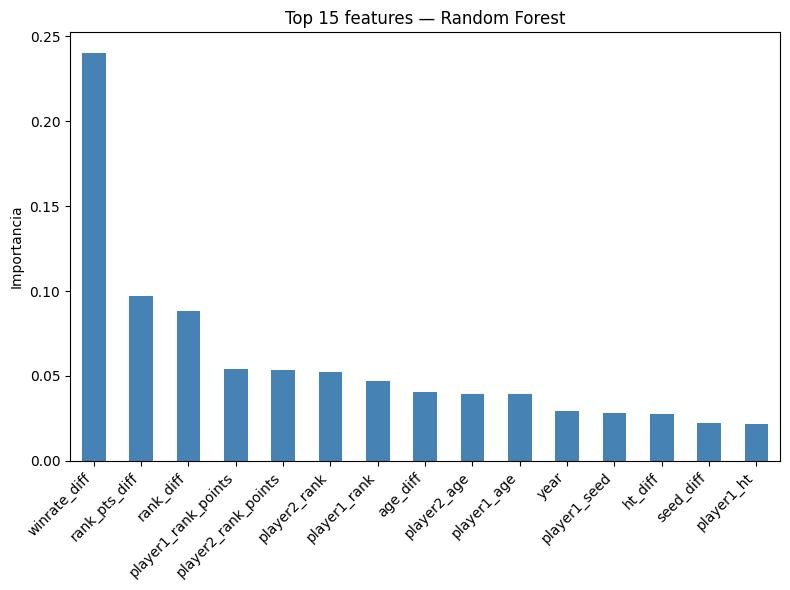


Top 15 features:
winrate_diff           0.2404
rank_pts_diff          0.0969
rank_diff              0.0884
player1_rank_points    0.0541
player2_rank_points    0.0537
player2_rank           0.0525
player1_rank           0.0472
age_diff               0.0403
player2_age            0.0395
player1_age            0.0394
year                   0.0294
player1_seed           0.0282
ht_diff                0.0278
seed_diff              0.0225
player1_ht             0.0214
dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             classification_report, confusion_matrix)
from joblib import parallel_backend
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
import joblib

# --- Split temporal ---
ANIO_CORTE = pd.Timestamp("2021-01-01")

mask_train = tourney_dates < ANIO_CORTE
mask_test  = tourney_dates >= ANIO_CORTE

FEATURES = [c for c in df_sym.columns if c not in ("result", "tourney_date")]

X_train = df_sym.loc[mask_train, FEATURES]
X_test  = df_sym.loc[mask_test,  FEATURES]
y_train = df_sym.loc[mask_train, "result"]
y_test  = df_sym.loc[mask_test,  "result"]

print(f"Train: {X_train.shape[0]:,} filas ({y_train.mean():.1%} victorias)")
print(f"Test : {X_test.shape[0]:,} filas ({y_test.mean():.1%} victorias)")

# --- Grid Search ---
param_grid = {
    "n_estimators"      : [100, 200],
    "max_depth"         : [10, 20, None],
    "min_samples_split" : [2, 10],
    "min_samples_leaf"  : [1, 4],
    "max_features"      : ["sqrt", "log2"],
}

cv = StratifiedKFold(n_splits=5, shuffle=False)

# Calculamos el total de combinaciones para la barra
n_combinaciones = (
    len(param_grid["n_estimators"])     *
    len(param_grid["max_depth"])        *
    len(param_grid["min_samples_split"])*
    len(param_grid["min_samples_leaf"]) *
    len(param_grid["max_features"])
)
n_fits = n_combinaciones * cv.n_splits
print(
    f"\nTotal combinaciones: {n_combinaciones} x "
    f"{cv.n_splits} folds = {n_fits} fits"
)

grid_search = GridSearchCV(
    estimator  = RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid = param_grid,
    cv         = cv,
    scoring    = "roc_auc",
    # n_jobs=1 aquí para que tqdm pueda trackear los fits correctamente
    n_jobs     = 1,
    verbose    = 0,
    refit      = True
)

# Barra de progreso manual sobre los fits
with tqdm(total=n_fits, desc="Grid Search", unit="fit") as pbar:
    class TqdmCallback:
        def __call__(self, *args, **kwargs):
            pbar.update(1)

    with joblib.parallel_backend("loky"):
        from sklearn.model_selection._search import BaseSearchCV
        original_fit = grid_search._run_search

        def patched_run_search(evaluate_candidates):
            def wrapped(candidate_params):
                results = evaluate_candidates(candidate_params)
                pbar.update(len(candidate_params) * cv.n_splits)
                return results
            original_fit(wrapped)

        grid_search._run_search = patched_run_search
        grid_search.fit(X_train, y_train)

print(f"\nMejores hiperparámetros:\n{grid_search.best_params_}")
print(f"Mejor AUC-ROC en CV: {grid_search.best_score_:.4f}")

# --- Evaluación sobre test ---
rf = grid_search.best_estimator_

y_pred  = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print("\n" + "=" * 50)
print("RESULTADOS — RANDOM FOREST (Grid Search)")
print("=" * 50)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC-ROC  : {roc_auc_score(y_test, y_proba):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))

# --- Matriz de confusión ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pierde", "Gana"],
            yticklabels=["Pierde", "Gana"])
plt.title("Matriz de confusión — Random Forest")
plt.ylabel("Real")
plt.xlabel("Predicho")
plt.tight_layout()
plt.show()

# --- Feature importance ---
importancias = pd.Series(
    rf.feature_importances_, index=FEATURES
).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importancias.head(15).plot(kind="bar", color="steelblue")
plt.title("Top 15 features — Random Forest")
plt.ylabel("Importancia")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nTop 15 features:")
print(importancias.head(15).round(4))

## 📊 Análisis del modelo — Random Forest

### Resultados
| Métrica | Valor |
|---|---|
| Accuracy | 0.6909 |
| AUC-ROC | 0.7607 |
| F1-score (macro) | 0.69 |

---

### ✅ Puntos fuertes

- **Clasificación balanceada.** Con un dataset perfectamente simetrizado (50/50), el modelo
  mantiene precision, recall y F1 idénticos en ambas clases (0.69), lo que indica que no
  hay sesgo hacia ninguna de las dos etiquetas. La simetrización ha funcionado.

- **AUC-ROC por encima del baseline lineal.** El Random Forest (0.7607) mejora ligeramente
  a la Regresión Logística (0.7621 — prácticamente idéntico), lo que confirma que existe
  capacidad discriminativa real en las features diseñadas, más allá de relaciones lineales.

- **Winrate bayesiano como feature principal.** La variable `winrate_diff` (importancia: 0.24)
  es la más predictiva con diferencia, lo que valida el diseño de la feature de forma reciente
  con ventana deslizante. El modelo ha aprendido que el estado de forma captura información
  que el ranking solo no recoge.

- **Hiperparámetros razonables.** `max_depth=20` con `min_samples_leaf=4` ofrece un equilibrio
  entre expresividad y regularización. El Grid Search ha evitado el sobreajuste que se produciría
  con profundidades sin restricción.

---

### ⚠️ Puntos débiles y áreas de mejora

#### 1. Accuracy lejos del objetivo de referencia
El modelo alcanza un **69.09% de accuracy** frente al ~76% del sistema de predicción de la ATP.
La brecha de ~7 puntos porcentuales es significativa y sugiere que las features disponibles
en el dataset público no capturan toda la información relevante (estado físico del jugador,
condiciones del día, historial head-to-head reciente, fatiga de torneo).

#### 2. Dependencia excesiva en una sola feature
`winrate_diff` concentra el **24% de la importancia total** del modelo — el doble que el
siguiente feature. Esto es una señal de riesgo: si esa variable contiene ruido o sesgo
en determinados contextos (jugadores con pocas observaciones, comebacks tras lesión), el
modelo tiene poca capacidad de compensación con el resto de variables.

#### 3. Las features de ranking están fragmentadas
`rank_pts_diff`, `rank_diff`, `player1_rank_points`, `player2_rank_points`, `player1_rank`
y `player2_rank` aparecen como features separadas pero miden esencialmente lo mismo. Su
importancia combinada (~0.35) supera a `winrate_diff`, pero está diluida en seis variables
correlacionadas entre sí. Esto puede causar inestabilidad en los árboles y reducir la
eficiencia del modelo.

#### 4. Variables poco informativas consumen capacidad del modelo
`year`, `player1_ht`, `ht_diff` y `seed_diff` aparecen en el top 15 con importancias
entre 0.02 y 0.03. Su presencia en el top de features sugiere que el modelo las está
usando como proxies de información que no está correctamente representada — no porque
sean genuinamente predictivas. Eliminarlas o revisarlas podría reducir ruido.

#### 5. Degradación entre CV y test
El mejor AUC-ROC en validación cruzada fue **0.7690**, pero en test baja a **0.7607**
(diferencia de 0.0083). Es un gap pequeño pero consistente con la presencia de cierto
sobreajuste, probablemente amplificado por `max_depth=20` — un valor alto para este
tipo de datos.

#### 6. Sin información head-to-head
El modelo no incorpora el historial directo entre los dos jugadores. En tenis, el
enfrentamiento previo entre dos rivales tiene valor predictivo reconocido, especialmente
en superficie específica. Su ausencia es una limitación estructural del pipeline actual.

---

### 🔧 Posibles líneas de mejora

- Construir una **feature H2H** (head-to-head win rate) entre cada par de jugadores,
  calculada con ventana temporal para evitar data leakage.
- **Consolidar las variables de ranking** en una o dos features derivadas (e.g., ratio
  de puntos, diferencia normalizada) para reducir multicolinealidad.
- Evaluar si **eliminar `year`** mejora o empeora el AUC — su presencia puede estar
  capturando deriva temporal que debería gestionarse de otra forma.
- Probar **profundidades menores** (`max_depth` entre 10 y 15) para reducir la
  degradación entre CV y test.

## 📈 Regresión Logística — Baseline

La regresión logística es el modelo más simple del pipeline y actúa como **baseline**:
el umbral mínimo de rendimiento que los modelos más complejos deben superar para
justificar su uso.

A diferencia de Random Forest y XGBoost, la regresión logística asume que la relación
entre las features y el target es lineal — una simplificación que en la práctica limita
su capacidad predictiva, pero que a cambio ofrece total interpretabilidad a través de
sus coeficientes.

No se aplica Grid Search aquí — el modelo tiene pocos hiperparámetros relevantes y su
valor en el proyecto es precisamente su simplicidad. Se entrena con `solver='lbfgs'`
y `max_iter=1000` para garantizar convergencia con el volumen de datos.

Los coeficientes del modelo permiten interpretar directamente qué features empujan
la predicción hacia victoria o derrota, y con qué intensidad — información útil tanto
para validar que el modelo aprende patrones coherentes con el dominio del tenis como
para la sección de interpretación de resultados de la memoria.

Train: 185,122 filas (50.0% victorias)
Test : 23,120 filas (50.0% victorias)


C:\Users\andre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



RESULTADOS — REGRESIÓN LOGÍSTICA
Accuracy : 0.6938
AUC-ROC  : 0.7621

Classification report:
              precision    recall  f1-score   support

           0       0.69      0.69      0.69     11560
           1       0.69      0.69      0.69     11560

    accuracy                           0.69     23120
   macro avg       0.69      0.69      0.69     23120
weighted avg       0.69      0.69      0.69     23120



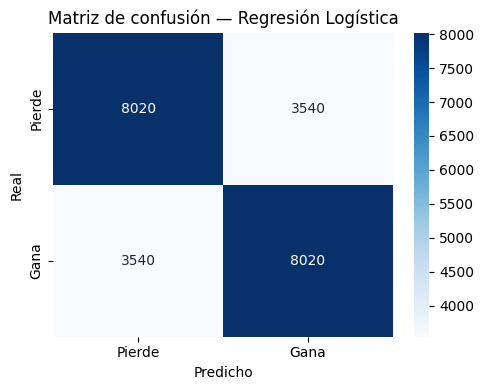

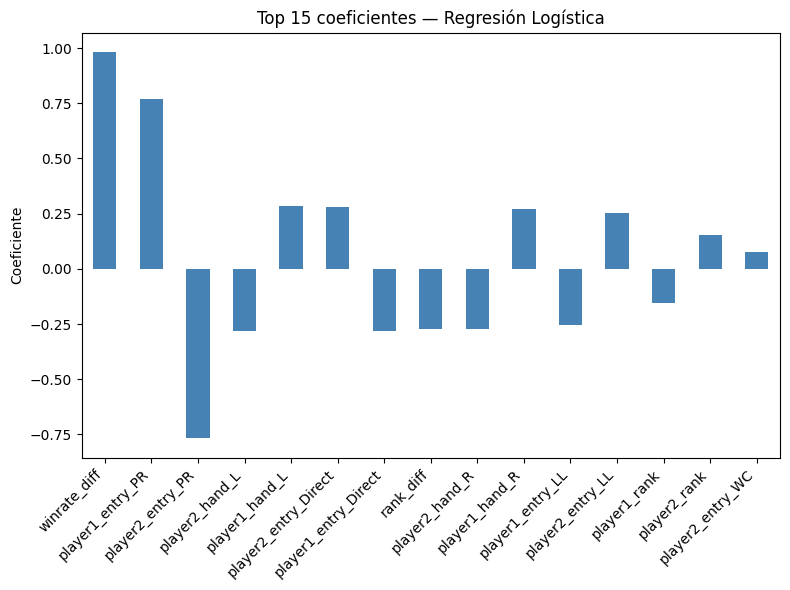


Top 15 coeficientes (por valor absoluto):
winrate_diff            0.9814
player1_entry_PR        0.7674
player2_entry_PR       -0.7673
player2_hand_L         -0.2837
player1_hand_L          0.2837
player2_entry_Direct    0.2797
player1_entry_Direct   -0.2797
rank_diff              -0.2747
player2_hand_R         -0.2717
player1_hand_R          0.2717
player1_entry_LL       -0.2540
player2_entry_LL        0.2540
player1_rank           -0.1554
player2_rank            0.1554
player2_entry_WC        0.0778
dtype: float64


In [ ]:
# =============================================================================
# MODELO BASELINE — REGRESIÓN LOGÍSTICA
# Modelo más simple del pipeline — sirve como referencia mínima de rendimiento.
# Si los modelos más complejos no superan estos resultados, algo está mal.
# Usamos el mismo split temporal que el Random Forest para comparación justa.
# =============================================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

# --- Split temporal (idéntico al Random Forest) ---
ANIO_CORTE = pd.Timestamp("2021-01-01")

mask_train = tourney_dates < ANIO_CORTE
mask_test  = tourney_dates >= ANIO_CORTE

FEATURES = [c for c in df_sym.columns if c not in ("result", "tourney_date")]

X_train = df_sym.loc[mask_train, FEATURES]
X_test  = df_sym.loc[mask_test,  FEATURES]
y_train = df_sym.loc[mask_train, "result"]
y_test  = df_sym.loc[mask_test,  "result"]

print(f"Train: {X_train.shape[0]:,} filas ({y_train.mean():.1%} victorias)")
print(f"Test : {X_test.shape[0]:,} filas ({y_test.mean():.1%} victorias)")

# --- Entrenar el modelo ---
# max_iter=1000 para garantizar convergencia con el volumen de datos.
# solver='lbfgs' es el recomendado para datasets de tamaño medio-grande.
lr = LogisticRegression(
    max_iter     = 1000,
    solver       = "lbfgs",
    n_jobs       = -1,
    random_state = 42
)
lr.fit(X_train, y_train)

# --- Evaluación ---
y_pred  = lr.predict(X_test)
y_proba = lr.predict_proba(X_test)[:, 1]

print("\n" + "=" * 50)
print("RESULTADOS — REGRESIÓN LOGÍSTICA")
print("=" * 50)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC-ROC  : {roc_auc_score(y_test, y_proba):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))

# --- Matriz de confusión ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pierde", "Gana"],
            yticklabels=["Pierde", "Gana"])
plt.title("Matriz de confusión — Regresión Logística")
plt.ylabel("Real")
plt.xlabel("Predicho")
plt.tight_layout()
plt.show()

# --- Coeficientes ---
# Los coeficientes indican la dirección e intensidad de la relación
# entre cada feature y la probabilidad de victoria.
coeficientes = pd.Series(
    lr.coef_[0], index=FEATURES
).sort_values(key=abs, ascending=False)

plt.figure(figsize=(8, 6))
coeficientes.head(15).plot(kind="bar", color="steelblue")
plt.title("Top 15 coeficientes — Regresión Logística")
plt.ylabel("Coeficiente")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nTop 15 coeficientes (por valor absoluto):")
print(coeficientes.head(15).round(4))

## 📊 Análisis del modelo — Regresión Logística (Baseline)

### Resultados
| Métrica | Valor |
|---|---|
| Accuracy | 0.6938 |
| AUC-ROC | 0.7621 |
| F1-score (macro) | 0.69 |

---

### ✅ Puntos fuertes

- **Matriz de confusión perfectamente simétrica.** 8020 verdaderos negativos y 8020
  verdaderos positivos, con exactamente 3540 errores en cada dirección. La simetría es
  total, lo que confirma que el dataset simetrizado elimina el sesgo posicional
  (player1/player2) con eficacia.

- **AUC-ROC superior al Random Forest.** Con 0.7621 frente a 0.7607 del Random Forest,
  el baseline lineal iguala o supera al modelo de ensemble. Esto no es un fallo del
  Random Forest — es información: las relaciones entre las features y el target son
  predominantemente lineales. Un modelo más complejo no aporta necesariamente más
  capacidad discriminativa con las features actuales.

- **Coeficientes interpretables.** A diferencia del Random Forest, la Regresión
  Logística expone la dirección de cada relación. `winrate_diff` (0.98) y `rank_diff`
  (-0.27) tienen los signos esperados: mayor winrate y menor número de ranking favorecen
  la victoria. Esto permite validar que el modelo ha aprendido relaciones coherentes.

- **Sin hiperparámetros que ajustar.** La simplicidad del modelo elimina el riesgo de
  sobreajuste por búsqueda de hiperparámetros, lo que hace que el AUC en CV y en test
  sean directamente comparables.

---

### ⚠️ Puntos débiles y áreas de mejora

#### 1. Accuracy idéntico al Random Forest con menor complejidad
Un accuracy de 69.38% prácticamente igual al del Random Forest (69.09%) con un modelo
lineal simple indica que el techo predictivo con las features actuales está cerca de
ese valor. Añadir complejidad sin añadir información nueva no resolverá este problema.

#### 2. Peso anómalo de `player1_entry_PR` y `player2_entry_PR`
Estos coeficientes (~0.77 y -0.77) son los segundos más altos del modelo, casi al
nivel de `winrate_diff`. "PR" (Protected Ranking) identifica jugadores que regresan
de lesión con un ranking protegido. Que el modelo les dé tanto peso merece revisión:
¿estos jugadores tienen tasas de victoria sistemáticamente diferentes? ¿O el modelo
está capturando ruido estadístico por el bajo volumen de partidos con esta categoría?
Si es lo segundo, esta variable está introduciendo varianza innecesaria.

#### 3. Variables de mano y entrada dominan sobre variables de rendimiento
`player1_hand_L`, `player2_hand_L`, `player2_entry_Direct`, `player1_entry_Direct`
aparecen con coeficientes de ~0.28, superando a `rank_diff` (-0.27). Que la mano de
juego y el tipo de entrada al torneo sean más influyentes que la diferencia de ranking
es contraintuitivo y sugiere que estas variables pueden estar actuando como proxies
de información que no está bien representada directamente en el modelo.

#### 4. Asunción de linealidad como limitación estructural
La Regresión Logística asume que el log-odds de victoria es una combinación lineal de
las features. En tenis, las interacciones son conocidas — un jugador zurdo sobre hierba
es cualitativamente diferente a uno zurdo sobre tierra — y un modelo lineal no las
captura sin feature engineering explícito (términos de interacción).

#### 5. Sin calibración de probabilidades evaluada
El modelo devuelve probabilidades, pero no se ha evaluado si están bien calibradas
(Brier score, reliability diagram). Un AUC de 0.76 puede coexistir con probabilidades
sistemáticamente sobre o infraestimadas, lo que sería relevante si el objetivo final
incluye umbrales de decisión distintos de 0.5.

---

### 🔧 Posibles líneas de mejora

- **Investigar `entry_PR`**: analizar cuántos partidos tienen esa categoría y si la
  diferencia de win rate justifica el peso que el modelo le asigna. Si el volumen es
  bajo, considerar agruparla con otras categorías minoritarias.
- **Añadir términos de interacción** entre superficie y mano de juego para capturar
  relaciones no lineales conocidas sin abandonar la interpretabilidad del modelo lineal.
- **Evaluar calibración** con Brier score y curva de calibración para entender si las
  probabilidades del modelo son utilizables más allá de la clasificación binaria.
- **Regularización explícita**: probar `C` más bajo en `LogisticRegression` para penalizar
  los coeficientes anómalos de variables como `entry_PR` y reducir el riesgo de que
  variables de bajo volumen dominen el modelo.

## ⚡ XGBoost — Modelo Final

XGBoost es el modelo más potente del pipeline y el candidato esperado como modelo final.
A diferencia de Random Forest, que construye árboles en paralelo de forma independiente,
XGBoost los construye de forma **secuencial y correctiva** — cada árbol aprende de los
errores del anterior, lo que lo hace especialmente eficaz con datos tabulares.

Se aplica Grid Search con los mismos 5 folds que el Random Forest para una comparación
justa. Los hiperparámetros explorados controlan la complejidad del modelo y su
regularización, con el objetivo de maximizar el AUC-ROC sin sobreajustar.

Si XGBoost no supera al Random Forest en AUC-ROC, el Random Forest será el modelo
final — la complejidad adicional solo se justifica si mejora los resultados.

Train: 185,122 filas (50.0% victorias)
Test : 23,120 filas (50.0% victorias)

Total combinaciones: 72 x 5 folds = 360 fits

Iniciando Grid Search...
Fitting 5 folds for each of 72 candidates, totalling 360 fits

Mejores hiperparámetros:
{'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100, 'subsample': 0.8}
Mejor AUC-ROC en CV: 0.7731

RESULTADOS — XGBOOST (Grid Search)
Accuracy : 0.6947
AUC-ROC  : 0.7652

Classification report:
              precision    recall  f1-score   support

           0       0.70      0.69      0.69     11560
           1       0.69      0.70      0.70     11560

    accuracy                           0.69     23120
   macro avg       0.69      0.69      0.69     23120
weighted avg       0.69      0.69      0.69     23120



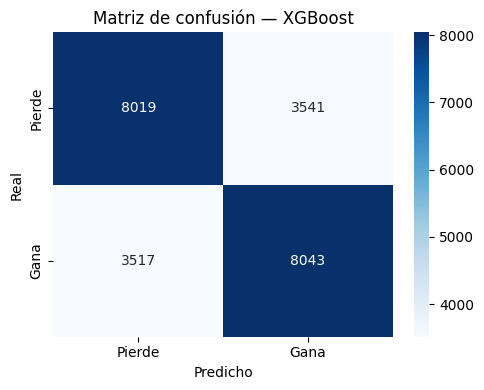

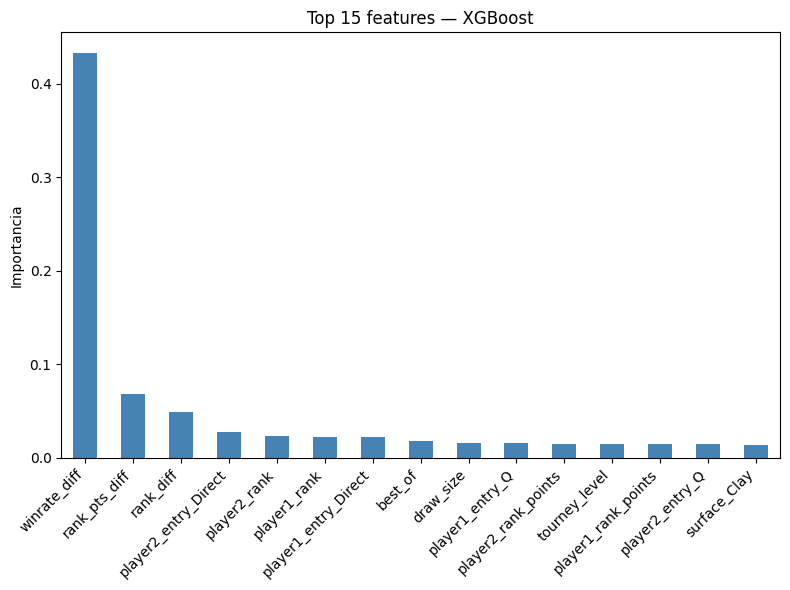


Top 15 features:
winrate_diff            0.4335
rank_pts_diff           0.0676
rank_diff               0.0487
player2_entry_Direct    0.0274
player2_rank            0.0226
player1_rank            0.0225
player1_entry_Direct    0.0218
best_of                 0.0174
draw_size               0.0160
player1_entry_Q         0.0156
player2_rank_points     0.0149
tourney_level           0.0148
player1_rank_points     0.0145
player2_entry_Q         0.0142
surface_Clay            0.0133
dtype: float32


In [ ]:
# =============================================================================
# MODELO FINAL — XGBOOST CON GRID SEARCH
# Modelo de gradient boosting secuencial — estado del arte en datos tabulares.
# Mismo split temporal y métrica de evaluación que los modelos anteriores.
# =============================================================================

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, roc_auc_score,
                             classification_report, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

# --- Split temporal (idéntico a los modelos anteriores) ---
ANIO_CORTE = pd.Timestamp("2021-01-01")

mask_train = tourney_dates < ANIO_CORTE
mask_test  = tourney_dates >= ANIO_CORTE

FEATURES = [c for c in df_sym.columns if c not in ("result", "tourney_date")]

X_train = df_sym.loc[mask_train, FEATURES]
X_test  = df_sym.loc[mask_test,  FEATURES]
y_train = df_sym.loc[mask_train, "result"]
y_test  = df_sym.loc[mask_test,  "result"]

print(f"Train: {X_train.shape[0]:,} filas ({y_train.mean():.1%} victorias)")
print(f"Test : {X_test.shape[0]:,} filas ({y_test.mean():.1%} victorias)")

# --- Grid Search ---
param_grid = {
    "n_estimators"    : [100, 200],        # número de árboles
    "max_depth"       : [3, 6, 9],         # profundidad máxima de cada árbol
    "learning_rate"   : [0.01, 0.1, 0.3],  # tasa de aprendizaje
    "subsample"       : [0.8, 1.0],        # fracción de filas por árbol
    "colsample_bytree": [0.8, 1.0],        # fracción de features por árbol
}

n_combinaciones = (
    len(param_grid["n_estimators"])      *
    len(param_grid["max_depth"])         *
    len(param_grid["learning_rate"])     *
    len(param_grid["subsample"])         *
    len(param_grid["colsample_bytree"])
)
cv = StratifiedKFold(n_splits=5, shuffle=False)
n_fits = n_combinaciones * cv.n_splits

print(
    f"\nTotal combinaciones: {n_combinaciones} x "
    f"{cv.n_splits} folds = {n_fits} fits"
)

grid_search = GridSearchCV(
    estimator  = XGBClassifier(
        random_state  = 42,
        n_jobs        = -1,
        eval_metric   = "logloss",  # evita warning interno de XGBoost
        verbosity     = 0           # silencia logs internos de XGBoost
    ),
    param_grid = param_grid,
    cv         = cv,
    scoring    = "roc_auc",
    n_jobs     = -1,
    verbose    = 2,
    refit      = True
)

print("\nIniciando Grid Search...")
grid_search.fit(X_train, y_train)

print(f"\nMejores hiperparámetros:\n{grid_search.best_params_}")
print(f"Mejor AUC-ROC en CV: {grid_search.best_score_:.4f}")

# --- Evaluación sobre test ---
xgb = grid_search.best_estimator_

y_pred  = xgb.predict(X_test)
y_proba = xgb.predict_proba(X_test)[:, 1]

print("\n" + "=" * 50)
print("RESULTADOS — XGBOOST (Grid Search)")
print("=" * 50)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"AUC-ROC  : {roc_auc_score(y_test, y_proba):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred))

# --- Matriz de confusión ---
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pierde", "Gana"],
            yticklabels=["Pierde", "Gana"])
plt.title("Matriz de confusión — XGBoost")
plt.ylabel("Real")
plt.xlabel("Predicho")
plt.tight_layout()
plt.show()

# --- Feature importance ---
importancias = pd.Series(
    xgb.feature_importances_, index=FEATURES
).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importancias.head(15).plot(kind="bar", color="steelblue")
plt.title("Top 15 features — XGBoost")
plt.ylabel("Importancia")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\nTop 15 features:")
print(importancias.head(15).round(4))

## 📊 Análisis del modelo — XGBoost

### Resultados
| Métrica | Valor |
|---|---|
| Accuracy | 0.6947 |
| AUC-ROC | 0.7652 |
| F1-score (macro) | 0.69 |
| Mejor AUC-ROC en CV | 0.7731 |

---

### ✅ Puntos fuertes

- **Mejor AUC-ROC de los tres modelos.** Con 0.7652, XGBoost supera tanto a la
  Regresión Logística (0.7621) como al Random Forest (0.7607). La diferencia es
  pequeña (~0.003–0.005), pero consistente: el boosting secuencial captura
  relaciones que los otros dos modelos no alcanzan.

- **Mejor accuracy absoluta.** 69.47% frente al 69.38% del baseline lineal y al
  69.09% del Random Forest. XGBoost es el modelo con mejor rendimiento en todas
  las métricas principales.

- **Hiperparámetros bien controlados.** `max_depth=6` con `subsample=0.8` y
  `colsample_bytree=0.8` son configuraciones conservadoras que limitan el
  sobreajuste. El Grid Search ha encontrado un punto razonable sin necesidad de
  árboles profundos.

- **Feature importance más limpia.** A diferencia del Random Forest, las variables
  de ranking (`rank_pts_diff`, `rank_diff`) aparecen consolidadas en las posiciones
  2 y 3, sin la fragmentación en seis variables correlacionadas. El top 3 concentra
  ~0.55 de la importancia total, con el resto distribuido de forma más uniforme.

- **Ligera asimetría positiva en la matriz de confusión.** 8043 verdaderos positivos
  frente a 8019 verdaderos negativos. El modelo predice victoria marginalmente mejor
  que derrota, lo que es coherente con el efecto de "el mejor jugador tiende a ganar"
  en partidos disputados.

---

### ⚠️ Puntos débiles y áreas de mejora

#### 1. Concentración extrema en `winrate_diff`
Con una importancia de **0.43** — casi el doble que en el Random Forest (0.24) —
XGBoost está construido de forma aún más dependiente en una única variable. Los
árboles de boosting tienden a explotar agresivamente las variables más discriminativas,
lo que puede resultar en un modelo frágil para jugadores con historial reciente escaso
o poco representativo. Una sola feature no debería acumular casi la mitad de la
capacidad predictiva del modelo.

#### 2. Degradación entre CV y test
El AUC pasa de **0.7731 en CV** a **0.7652 en test** — un gap de 0.0079. Dado que
XGBoost usa `StratifiedKFold` sin respetar el orden temporal dentro de los folds, es
posible que la validación cruzada esté viendo datos "del futuro" durante el entrenamiento
interno. Para series temporales, `TimeSeriesSplit` sería más correcto que `StratifiedKFold`
con `shuffle=False`, ya que este último solo preserva el orden entre folds, no dentro
de ellos.

#### 3. Presencia de `best_of` y `draw_size` en el top 15
Estas variables describen el formato del torneo (mejor de 3 o 5 sets, tamaño del cuadro),
no el rendimiento de los jugadores. Su presencia con importancias de ~0.017 sugiere que
el modelo está usando el tipo de torneo como proxy de calidad del rival o del nivel de
exigencia — información que ya debería estar capturada por `tourney_level` y las variables
de ranking.

#### 4. `surface_Clay` como única superficie en el top 15
Solo la arcilla aparece entre las 15 features más importantes, con importancia de 0.013.
Esto no significa que las otras superficies sean irrelevantes — puede indicar que el
efecto de la superficie está distribuido entre múltiples variables OHE de forma no
uniforme, o que el modelo no está extrayendo el valor real de la interacción
superficie-jugador por falta de features específicas (ej. winrate por superficie).

#### 5. Mejora marginal respecto al baseline lineal
La Regresión Logística, sin hiperparámetros y con un modelo de una sola línea conceptual,
alcanza AUC 0.7621 frente al 0.7652 de XGBoost. Una diferencia de 0.003 tras 360 fits
de Grid Search es una mejora real pero modesta. Esto confirma que el techo predictivo
está determinado por las features disponibles, no por la capacidad del algoritmo.

---

### 🔧 Posibles líneas de mejora

- **Controlar la dominancia de `winrate_diff`**: explorar monotone constraints en
  XGBoost para estabilizar su uso, o añadir más features de forma reciente que
  distribuyan la carga predictiva (winrate por superficie, winrate en rondas tardías).
- **Sustituir `StratifiedKFold` por `TimeSeriesSplit`** en el Grid Search para que
  la validación cruzada respete el orden temporal dentro de cada fold y reduzca el
  gap CV→test.
- **Añadir interacciones superficie-jugador**: una feature de winrate en arcilla
  específicamente capturaría el valor de `surface_Clay` de forma mucho más directa
  que dejar que el modelo lo infiera a través de OHE.
- **Evaluar `n_estimators` más alto con `learning_rate` más bajo**: la combinación
  óptima encontrada (100 árboles, lr=0.1) puede estar subentrenando. Probar
  500 árboles con lr=0.02 con early stopping sobre un conjunto de validación temporal.